# Práctica de detección de objetos

### **Grupo:** N — **Integrantes:** Lucas Amado Oseira y María Lestón Geada
##### **Dataset:** Lettuce Pallets (`Francesco/lettuce-pallets`)
##### **Detectores:** Cascade R-CNN (Detectron2) y SSD300-VGG16 (Torchvision), ambos preentrenados en MS COCO

## Cómo usar este cuaderno y resumen de decisiones

**Orden de trabajo (se ejecuta de arriba abajo, en Colab con GPU T4):**
1. Instalar dependencias → 2. Configurar → 3. Cargar y limpiar los datos → 4. Analizar el dataset →
5. Baseline SSD300 → 6. Baseline Cascade R-CNN → 7. Mejoras (E1–E6) → 8. Resultados y análisis de fallos.

Cada entrenamiento guarda su checkpoint y sus predicciones en Drive: si Colab se desconecta, **se vuelve a ejecutar el cuaderno entero y lo ya entrenado se reutiliza**
(solo se recalcula la evaluación). Los resultados de todos los experimentos se acumulan en `results.csv`.

**Resumen de decisiones (cada una se justifica en su sección):**

| Decisión | Elección | Motivo breve |
|---|---|---|
| Clases | Se elimina `lettuce` (id 0) → 5 clases | Es la categoría "padre" de Roboflow, sin anotaciones; el guion habla de 5 clases |
| Protocolo | Entrenar en *train*, elegir en *val*, reportar *test* | Evita sobreajustar las decisiones al test |
| Baseline | Fine-tuning de pesos COCO, **sin aumento de datos**, un solo LR | Punto de partida limpio: cada mejora cambia **una** cosa |
| Evaluación | Mismo código (`evaluate_coco`) y mismos umbrales para ambos detectores | Comparación justa SSD vs Cascade |
| Mejoras | Aumento de datos, LR diferenciado, combinación, TTA, ensemble | Cada una responde a una característica concreta del dataset |

## 1. Imports y configuración del entorno

Ejecutamos esta celda una vez por sesión nueva de Colab con GPU T4. Detectron2 se compila desde el repositorio oficial (tarda varios minutos).
Si Colab pide reiniciar la sesión, reiniciamos y continuamos desde la celda de imports.

In [1]:
# Dependencias de evaluación y ensembles
!pip -q install pycocotools ensemble-boxes

# Detectron2 se compila desde el repositorio (tarda varios minutos)
!pip -q install 'git+https://github.com/facebookresearch/detectron2.git' --no-build-isolation

  Preparing metadata (pyproject.toml) ... done


Importamos las librerías necesarias para realizar la práctica.

In [2]:
import os, sys, io, json, time, math, copy, random, tarfile, contextlib, gc, importlib.util
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torchvision
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# Importamos las librerías de pycocotools para la evaluación del modelo y el manejo del dataset COCO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Importamos las librerías de Detectron2 para la configuración, entrenamiento y evaluación del modelo
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.evaluation import COCOEvaluator
from detectron2.data import (DatasetCatalog, MetadataCatalog, DatasetMapper,
                                build_detection_train_loader, transforms as T)
from detectron2.data.datasets import register_coco_instances

/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Esta se realizará en Google Colab para garantizar la velocidad en la obtención de los resultados. Tambien definimos varias constantes: la ruta al zip que contiene los CSVs que utilizaremos, la ruta al directorio en el que se descomprimirá dicho zip y el dispositivo que se empleará en el entrenamiento. Además, fijaremos una semilla que nos garantice la reproducibilidad de los resultados.

In [3]:
SEED = 2710
DATASET_NAME = "lettuce-pallets"

DRIVE_TAR = "/content/drive/MyDrive/vision_p6/dataset.tar.gz" # dataset ya subido a Drive
USE_DRIVE = True                                              # guardamos los resultados en Drive
DRIVE_WORK_DIR = "/content/drive/MyDrive/vision_p6/work" # guardamos los resultados en Drive
LOCAL_WORK_DIR = "work" # guardamos los resultados en local si no usamos Drive

PRETRAINED = True # pesos preentrenados en COCO

# Parámetros de inferencia comunes a ambos detectores
SCORE_THRESH_EVAL = 0.001
NMS_IOU = 0.5
MAX_DETS = 300

SPLITS = ("train", "val", "test")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


In [4]:
# Fijamos todas las semillas para asegurar la reproducibilidad de los experimentos
def seed_everything(seed=SEED, deterministic=True):
    """Fija todas las semillas. 'deterministic' hace cuDNN determinista (algo más lento)."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# Función para fijar la semilla de los workers del DataLoader, si no el aumento de datos no es reproducible
def seed_worker(worker_id):
    np.random.seed(SEED + worker_id)
    random.seed(SEED + worker_id)

# Creamos un generador de números aleatorios para el DataLoader, que se utilizará para inicializar los workers y garantizar la reproducibilidad
def make_generator(seed=SEED):
    return torch.Generator().manual_seed(seed)

seed_everything() # Fijamos la semilla

# Detectamos si estamos en Google Colab para montar el Drive y establecer el directorio de trabajo
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path(DRIVE_WORK_DIR)
else:
    WORK_DIR = Path(LOCAL_WORK_DIR)

# Creamos los subdirectorios necesarios para almacenar los resultados del entrenamiento y la evaluación
for sub in ("ckpt", "preds", "figs", "d2"):
    (WORK_DIR / sub).mkdir(parents=True, exist_ok=True)

# Creamos los subdirectorios necesarios para almacenar los datos limpios y procesados del dataset
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
CLEAN_DIR = DATA_DIR / "clean" # directorio para almacenar los datos limpios y procesados del dataset
CLEAN_DIR.mkdir(exist_ok=True)
print("WORK_DIR:", WORK_DIR.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WORK_DIR: /content/drive/MyDrive/vision_p6/work


## 2. Datos: extracción, limpieza y formato unificado

Comenzaremos a tratar los datos extrayendo el `dataset.tar.gz` y localizar el JSON y la carpeta de imágenes de cada split. Localizamos los splits por el nombre exacto de la carpeta (`train`, `valid`, `test`) de forma robusta.

In [5]:
SPLIT_DIR_ALIASES = {"train": "train", "valid": "val", "validation": "val", "val": "val", "test": "test"}

# Extraemos el tar.gz si el destino está vacío, ya que en Colab se borrará al cerrar la sesión
def extract_tar(tar_path, dest):
    """Extrae el tar.gz si el destino está vacío (en Colab /content se borra al cerrar la sesión)."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    if not any(dest.iterdir()):
        with tarfile.open(tar_path, "r:gz") as tar:
            try: tar.extractall(dest, filter="data")
            except TypeError: tar.extractall(dest)
    return dest

# Localizamos los splits de entrenamiento, validación y test en el dataset extraído
def locate_raw_splits(root):
    raw = {}
    for js in Path(root).rglob("*.json"):
        key = SPLIT_DIR_ALIASES.get(js.parent.name.lower())
        if key and key not in raw:
            raw[key] = {"json": js, "images": js.parent} # en Roboflow, las imágenes están junto al JSON
    missing = [s for s in SPLITS if s not in raw]
    assert not missing, f"Faltan splits: {missing}"
    return raw

# Mostramos los paths de los splits localizados
RAW = locate_raw_splits(extract_tar(DRIVE_TAR, DATA_DIR / "raw"))
for s in SPLITS: print(f"{s}: {RAW[s]['json']}")

train: data/raw/home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/train/_annotations.coco.json
val: data/raw/home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/valid/_annotations.coco.json
test: data/raw/home/zuppif/Documents/Work/RoboFlow/ODinW-RF100-challenge/rf100/lettuce-pallets/test/_annotations.coco.json


A continuación, cargamos el dataset de entrenamiento COCO y mostramos información sobre las distintas categorías de lechuga y las anotaciones existentes para cada imagen.

In [6]:
# Información del dataset ANTES de la limpieza (lee el JSON original de Roboflow)
raw_train = COCO(str(RAW["train"]["json"]))
raw_cats = sorted(raw_train.loadCats(raw_train.getCatIds()), key=lambda x: x["id"])

print("\nCategorías COCO (originales):", [(c["id"], c["name"]) for c in raw_cats])
print(f"Total imágenes de entrenamiento: {len(raw_train.getImgIds())}")
print(f"Número de anotaciones train: {len(raw_train.getAnnIds())}")

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!

Categorías COCO (originales): [(0, 'lettuce'), (1, 'Ready'), (2, 'empty_pod'), (3, 'germination'), (4, 'pod'), (5, 'young')]
Total imágenes de entrenamiento: 1060
Número de anotaciones train: 13812


En principio vemos que existen 6 categorías distintas: *'lettuce', 'Ready', 'empty_pod', 'germination', 'pod'* y *'young'*, repartidas entre 1060 imágenes de entrenamiento y con un total de 13812 anotaciones.

Mostramos las anotaciones por categoría.

In [ ]:
for c in raw_cats:
    n = len(raw_train.getAnnIds(catIds=[c["id"]]))
    print(f"  id {c['id']}: {c['name']:11s} -> {n} anotaciones")

  id 0: lettuce     -> 0 anotaciones
  id 1: Ready       -> 1387 anotaciones
  id 2: empty_pod   -> 1100 anotaciones
  id 3: germination -> 4651 anotaciones
  id 4: pod         -> 2531 anotaciones
  id 5: young       -> 4143 anotaciones


Comprobamos que todas las categorías tienen anotaciones menos `lettuce`.

**Paso:** limpiar las anotaciones y crear un JSON limpio por split.

**Decisiones y justificación:**
1. **Eliminar la categoría `lettuce` (id 0).** En Roboflow es la categoría "padre" del dataset y no tiene anotaciones propias. Si se dejara, el modelo
   tendría 6 clases en vez de las 5 reales del guion, con una clase "fantasma" que nunca aparece.
2. **Renumerar las clases a 1…5.** En torchvision la etiqueta 0 es el fondo; con ids contiguos 1…5 la etiqueta del modelo **coincide** con el `category_id`
   y no hace falta ninguna conversión (la versión anterior restaba 1 al evaluar y desplazaba todas las clases).
3. **Recortar las cajas a la imagen y descartar las degeneradas** (ancho o alto < 1 px): una caja de tamaño nulo provoca errores y pérdidas `NaN` al entrenar.
4. **Se conservan las imágenes sin objetos** (en el JSON): se usan en la evaluación; Detectron2 las ignora solo al entrenar.

In [8]:
def build_clean_coco(raw, out_dir):
    """Genera un JSON COCO limpio por split. Devuelve (CLEAN, class_names, class_ids)."""
    # Creamos el directorio de salida si no existe
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    # Leemos el JSON de entrenamiento original y obtenemos los nombres de las categorías y los IDs utilizados
    train = json.loads(Path(raw["train"]["json"]).read_text())
    old_names = {c["id"]: c["name"] for c in train["categories"]}
    used_ids = sorted({a["category_id"] for a in train["annotations"]})
    dropped = [n for i, n in old_names.items() if i not in used_ids] # categorías descartadas
    print("Categorías descartadas (sin anotaciones en train):", dropped)

    # Creamos un diccionario que mapea los nombres de las categorías a nuevos IDs consecutivos (1..K) para las categorías utilizadas
    name2new = {old_names[i]: n + 1 for n, i in enumerate(used_ids)}

    # Iteramos sobre cada split y generamos un nuevo JSON COCO limpio
    # Descartamos anotaciones de categorías no utilizadas y cajas degeneradas
    clean = {}
    for split in SPLITS:
        d = json.loads(Path(raw[split]["json"]).read_text())
        id2name = {c["id"]: c["name"] for c in d["categories"]}
        imgs = {im["id"]: im for im in d["images"]}
        new_anns, stats = [], Counter()
        
        for a in d["annotations"]:
            name = id2name.get(a["category_id"])
            
            # Descartamos cajas degeneradas (cajas con ancho o alto menor que 1 píxel)
            im = imgs[a["image_id"]]; x, y, w, h = a["bbox"]
            x1, y1 = max(0.0, x), max(0.0, y)
            x2, y2 = min(float(im["width"]), x + w), min(float(im["height"]), y + h)
            if x2 - x1 < 1 or y2 - y1 < 1:
                stats["caja_degenerada"] += 1
                continue
            
            # Creamos la nueva anotación con el nuevo ID de categoría y la caja ajustada
            new_anns.append({"id": len(new_anns) + 1, "image_id": a["image_id"],
                             "category_id": name2new[name], "bbox": [x1, y1, x2 - x1, y2 - y1],
                             "area": (x2 - x1) * (y2 - y1), "iscrowd": 0})
        
        # Guardamos el nuevo JSON COCO limpio para el split actual
        out = {"images": d["images"], "annotations": new_anns,
               "categories": [{"id": i, "name": n} for n, i in name2new.items()]}
        
        # Guardamos el JSON limpio en el directorio de salida y almacenamos la información del split en el diccionario 'clean'
        p = out_dir / f"{split}_clean.json"; p.write_text(json.dumps(out))
        clean[split] = {"json": p, "images": Path(raw[split]["images"])}
        print(f"{split:5s}: {len(d['images'])} imgs | {len(d['annotations'])} -> {len(new_anns)} anotaciones | descartes: {dict(stats)}")
    names = list(name2new.keys())
    ids = list(name2new.values())
    return clean, names, ids

CLEAN, CLASS_NAMES, CLASS_IDS = build_clean_coco(RAW, CLEAN_DIR)
K = len(CLASS_NAMES) # nº de clases reales
# Creamos un diccionario que mapea los IDs de las clases a sus índices
CID2IDX = {c: i for i, c in enumerate(CLASS_IDS)}
print(f"\nK = {K} clases:", dict(zip(CLASS_IDS, CLASS_NAMES)))

# Creamos un diccionario que mapea los splits a sus objetos COCO correspondientes para facilitar la evaluación
COCO_GT = {s: COCO(str(CLEAN[s]["json"])) for s in SPLITS}

Categorías descartadas (sin anotaciones en train): ['lettuce']
train: 1060 imgs | 13812 -> 13812 anotaciones | descartes: {}
val  : 299 imgs | 3867 -> 3866 anotaciones | descartes: {'caja_degenerada': 1}
test : 151 imgs | 2042 -> 2042 anotaciones | descartes: {}

K = 5 clases: {1: 'Ready', 2: 'empty_pod', 3: 'germination', 4: 'pod', 5: 'young'}
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


## 3. Análisis exploratorio del dataset

**Paso:** medir las características que condicionan el diseño de las mejoras: reparto de clases, nº de objetos por imagen y **tamaño de los objetos**.
Es lo que pide el guion en la exposición (punto 1) y lo que **justifica** las decisiones de la fase de mejora.

**Qué buscamos y por qué importa:**
- *Desbalance de clases* → si hay clases raras, plantear muestreo balanceado o ponderar la pérdida.
- *Tamaño de objeto* → SSD300 reescala **todas** las imágenes a 300×300; los objetos pequeños pierden detalle. Calculamos el tamaño efectivo tras el reescalado.
- *Vista cenital* → no hay "arriba/abajo" privilegiado: los giros y volteos de la imagen producen escenas igual de realistas (justifica el aumento geométrico).

In [16]:
# Creamos un DataFrame con las anotaciones de todos los splits
# Incluimos información sobre el tamaño y la relación de aspecto de cada objeto
def annotations_dataframe(coco, split):
    rows = []
    for a in coco.anns.values():
        im = coco.imgs[a["image_id"]]

        # Calculamos el área de la caja delimitadora
        x, y, w, h = a["bbox"]
        area = w * h

        # Agregamos la información al DataFrame
        rows.append({"split": split, "image_id": a["image_id"],
                     "cls": CLASS_NAMES[CID2IDX[a["category_id"]]], # nombre de la clase
                     "w": w, "h": h, "area": area, # área de la caja delimitadora
                     "sqrt_area": math.sqrt(area), # raíz cuadrada del área de la caja delimitadora
                     "rel_size": math.sqrt(area / (im["width"] * im["height"])), # tamaño relativo del objeto respecto al tamaño de la imagen
                     "aspect": w / h}) # relación entre el ancho y el alto de la caja delimitadora
    df = pd.DataFrame(rows)
    # Clasificamos los objetos en categorías de tamaño: pequeño, mediano y grande según el área de la caja delimitadora
    # Los límites de las categorías se establecen en 32^2 y 96^2 píxeles cuadrados, según la convención de COCO
    df["size_cat"] = pd.cut(df["area"], [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
    return df

# Creamos el DataFrame con las anotaciones para todos los splits
ANN_DF = pd.concat([annotations_dataframe(COCO_GT[s], s) for s in SPLITS], ignore_index=True)

# Mostramos un resumen de las imágenes y anotaciones por split
print("Imágenes y anotaciones por split:")
summary = []
for s in SPLITS:
    c = COCO_GT[s]
    per_img = Counter(a["image_id"] for a in c.anns.values()) # contamos el número de anotaciones por imagen
    n_img = len(c.imgs)
    n_empty = sum(1 for i in c.imgs if per_img.get(i, 0) == 0) # contamos el número de imágenes sin anotaciones
    summary.append({"split": s, "imágenes": n_img, "anotaciones": len(c.anns), "imgs_sin_objetos": n_empty,
                    "objs/img media": round(len(c.anns) / n_img, 1), # número medio de objetos por imagen
                    "objs/img máx": max(per_img.values())}) # número máximo de objetos en una imagen
display(pd.DataFrame(summary).set_index("split"))

# Mostramos un resumen de las anotaciones por clase y split
print("\nAnotaciones por clase y split:")
class_counts = ANN_DF.pivot_table(index="cls", columns="split", values="area", aggfunc="count").reindex(CLASS_NAMES)[list(SPLITS)]
class_counts["% train"] = (100 * class_counts["train"] / class_counts["train"].sum()).round(1)
display(class_counts)

# Mostramos un resumen de la resolución de las imágenes en el dataset
print("\nResolución de las imágenes:")
display(pd.Series([(im["width"], im["height"]) for c in COCO_GT.values() for im in c.imgs.values()]).value_counts().head())

# SSD300 redimensiona todas las imágenes a 300x300
# Calculamos el tamaño efectivo del objeto en píxeles tras el reescalado a 300x300 píxeles
ANN_DF["px_ssd300"] = ANN_DF["rel_size"] * 300
tr = ANN_DF[ANN_DF.split == "train"]

# Mostramos un resumen de la distribución del tamaño de los objetos en el conjunto de entrenamiento
print("\nTamaño de objeto (train):", tr["size_cat"].value_counts(normalize=True).round(3).to_dict())

# Mostramos un resumen de la raíz cuadrada del área de los objetos en píxeles originales y sus cuantiles
print("sqrt(área) px originales, cuantiles:", tr["sqrt_area"].quantile([.05, .25, .5, .75, .95]).round(1).to_dict())

# Mostramos un resumen del porcentaje de objetos con tamaño efectivo menor a 16 píxeles en SSD300
# Los objetos muy pequeños pueden ser difíciles de detectar para el modelo SSD300
# Este porcentaje nos da una idea de cuántos objetos podrían ser problemáticos en términos de detección
print(f"% objetos con tamaño efectivo < 16 px en SSD300: {100*(tr['px_ssd300'] < 16).mean():.1f}%")

Imágenes y anotaciones por split:


,imágenes,anotaciones,imgs_sin_objetos,objs/img media,objs/img máx
split,,,,,
train,1060,13812,8,13.0,20
val,299,3866,0,12.9,20
test,151,2042,1,13.5,21



Anotaciones por clase y split:


split,train,val,test,% train
cls,,,,
Ready,1387,376,246,10.0
empty_pod,1100,311,182,8.0
germination,4651,1321,631,33.7
pod,2531,725,337,18.3
young,4143,1133,646,30.0



Resolución de las imágenes:


,count
"(640, 640)",1510



Tamaño de objeto (train): {'medium': 0.632, 'large': 0.368, 'small': 0.0}
sqrt(área) px originales, cuantiles: {0.05: 49.1, 0.25: 62.5, 0.5: 80.9, 0.75: 122.0, 0.95: 220.0}
% objetos con tamaño efectivo < 16 px en SSD300: 0.0%


Mostramos un resumen gráfico de las anotaciones por clase, el número de objetos por imagen, la distribución del tamaño de los objetos y la relación de aspecto de las cajas delimitadoras.

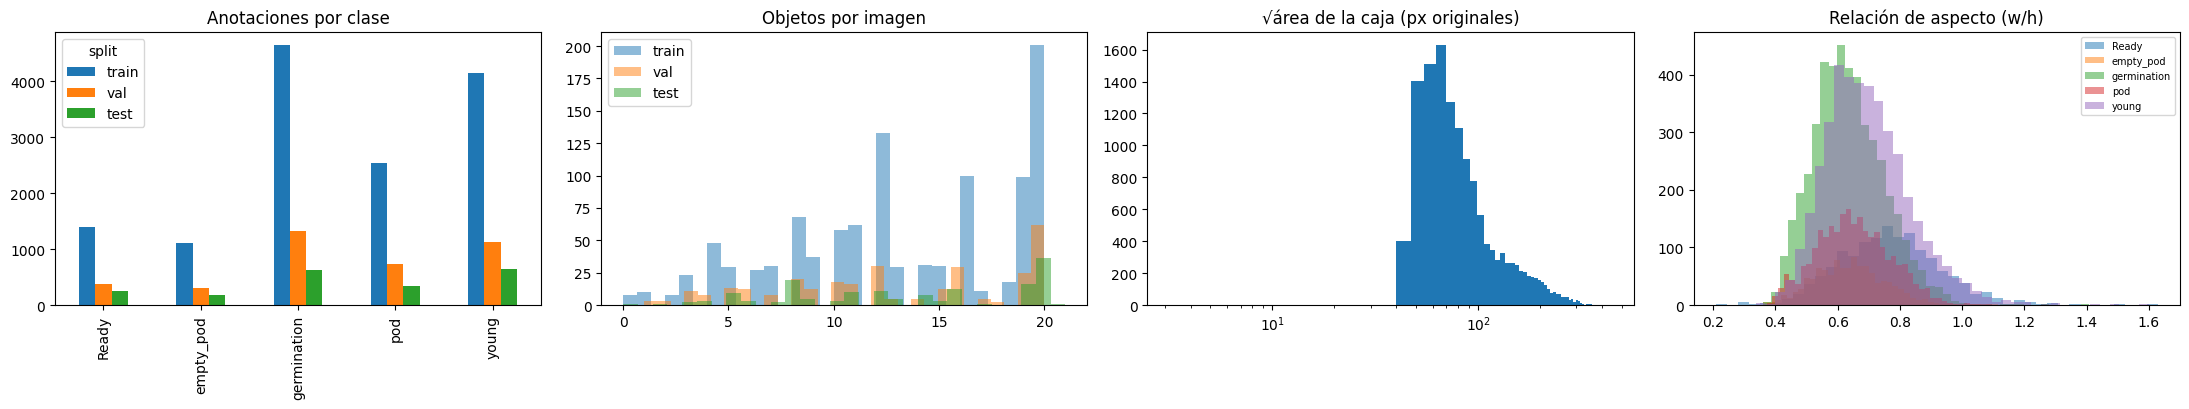

sqrt_area              px_ssd300             
               median   min    max    median   min    max
cls                                                      
Ready           187.2  58.0  444.5      87.8  27.2  208.4
empty_pod        74.2  42.5  135.9      34.8  19.9   63.7
germination      67.7  40.2  157.5      31.7  18.8   73.8
pod              64.1  38.9  242.0      30.0  18.3  113.4
young           123.4   3.2  355.3      57.8   1.5  166.6

In [23]:
fig, axs = plt.subplots(1, 4, figsize=(22, 4.2))

# Mostramos un gráfico de barras con el número de anotaciones por clase para cada split
class_counts[list(SPLITS)].plot.bar(ax=axs[0]); axs[0].set_title("Anotaciones por clase"); axs[0].set_xlabel("")

# Mostramos un histograma con el número de objetos por imagen para cada split
for s in SPLITS:
    cnt = Counter(a["image_id"] for a in COCO_GT[s].anns.values())
    axs[1].hist([cnt.get(i, 0) for i in COCO_GT[s].imgs], bins=30, alpha=.5, label=s)
axs[1].set_title("Objetos por imagen")
axs[1].legend()

# Mostramos un histograma que refleje la distribución del tamaño de los objetos
axs[2].hist(tr["sqrt_area"], bins=60)
axs[2].set_xscale("log")
axs[2].set_title("√área de la caja (px originales)")

# Mostramos un histograma con la relación de aspecto (ancho/alto) de los objetos por clase
for cls in CLASS_NAMES:
    axs[3].hist(tr[tr.cls == cls]["aspect"].clip(0, 4), bins=40, alpha=.5, label=cls)
axs[3].set_title("Relación de aspecto (w/h)")
axs[3].legend(fontsize=7)

plt.tight_layout()
plt.savefig(WORK_DIR / "figs" / "eda_overview.png", dpi=130)
plt.show()

# Mostramos el tamaño medio por clase para ver si hay clases sistemáticamente más pequeñas
# Esto puede ser relevante para la detección, ya que las clases más pequeñas pueden ser más difíciles de detectar para el modelo
display(tr.groupby("cls")[["sqrt_area", "px_ssd300"]].agg(["median", "min", "max"]).round(1).reindex(CLASS_NAMES))

Lo siguiente que haremos será mostrar algunas de las imágenes de entrenamiento con sus respectivos tamaños y anotaciones.

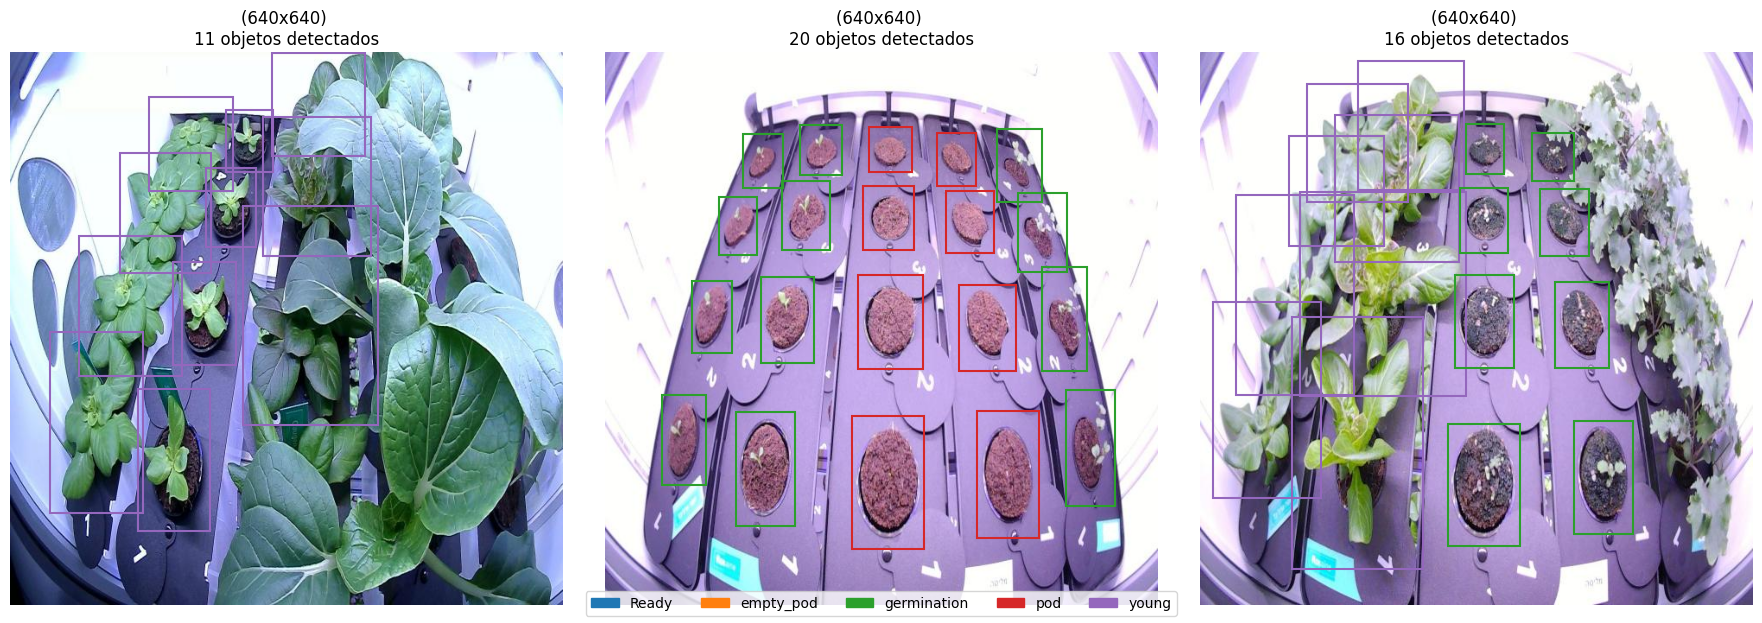

In [45]:
# Creamos un array de colores para cada clase utilizando el colormap 'tab10' de Matplotlib
CLASS_COLORS = plt.cm.tab10(np.arange(K))

def draw_gt(coco, image_dir, image_ids, ncols=3):
    nrows = math.ceil(len(image_ids) / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows)); axs = np.atleast_1d(axs).ravel()
    for ax in axs: ax.axis("off")
    for ax, iid in zip(axs, image_ids):
        info = coco.imgs[iid]
        ax.imshow(Image.open(Path(image_dir) / info["file_name"]).convert("RGB"))
        n_obj = 0
        for a in coco.loadAnns(coco.getAnnIds(imgIds=iid)):
            x, y, w, h = a["bbox"]
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, lw=1.5, ec=CLASS_COLORS[CID2IDX[a["category_id"]]]))
            n_obj += 1
        ax.set_title(f"({info['width']}x{info['height']}) \n{n_obj} objetos detectados")
    handles = [patches.Patch(color=CLASS_COLORS[i], label=n) for i, n in enumerate(CLASS_NAMES)]
    fig.legend(handles=handles, loc="lower center", ncol=K)
    plt.tight_layout(); plt.show()

rng = random.Random(SEED)
draw_gt(COCO_GT["train"], CLEAN["train"]["images"], rng.sample(sorted(COCO_GT["train"].imgs), 3))

### ✏️ Completar con las cifras de las celdas anteriores (1 diapositiva)
- Clase más/menos frecuente y su % en train: _…_
- % de objetos *small/medium/large* y % por debajo de 16 px en SSD300: _…_
- Objetos por imagen (media/máximo) y si `MAX_DETS=300` es suficiente: _…_
- Retos visuales observados en las imágenes (oclusión, parecido entre clases, iluminación…): _…_

## 4. Infraestructura común: dataset, evaluación, tiempos y resultados

Seguidamente, creamos una clase que cargue el dataset COCO y prepare los datos tanto para entrenamiento como para evaluación.

In [12]:
class CocoDetection(Dataset):
    def __init__(self, ann_file, image_dir, train=False):
        self.coco = COCO(str(ann_file))
        self.image_dir = Path(image_dir)
        self.ids = list(sorted(self.coco.getImgIds()))
        self.train = train

    def __len__(self):
        return len(self.ids)

    def _image_path(self, file_name):
        p = self.image_dir / file_name
        if p.exists():
            return p
        else:
            raise FileNotFoundError(f"Image file not found: {p}")

    def __getitem__(self, index):
        img_id = self.ids[index]
        img_info = self.coco.loadImgs(img_id)[0]
        image = Image.open(self._image_path(img_info["file_name"])).convert("RGB")

        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)

        boxes = []
        labels = []

        for ann in anns:
            x, y, w, h = ann["bbox"]
            boxes.append([x, y, x + w, y + h])
            labels.append(ann["category_id"])

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([img_id]),
        }

        if self.train:
            # Apply any data augmentation here if needed
            pass

        return image, target

def collate_fn(batch):
    return tuple(zip(*batch))

# Creamos los DataLoaders para entrenamiento y validación, que servirán para alimentar el modelo durante el entrenamiento y la evaluación
# Se utiliza un tamaño de batch de 4 y se aplica la función de colación personalizada para manejar los datos de manera adecuada
train_ds = CocoDetection(ANN_FILES["train"], IMAGE_DIRS["train"], train=True)
val_ds = CocoDetection(ANN_FILES["val"], IMAGE_DIRS["val"], train=False)
test_ds = CocoDetection(ANN_FILES["test"], IMAGE_DIRS["test"], train=False)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, collate_fn=collate_fn)

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


Una vez creados los DataLoaders procedemos a construir el detector SSD300 con VGG16 como backbone, utilizando pesos preentrenados en COCO y adaptando la cabeza de clasificación para nuestras clases específicas.

In [13]:
from torchvision.models.detection import ssd300_vgg16
from torchvision.models.detection import SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead

def build_ssd(pretrained=True):
    weights = SSD300_VGG16_Weights.COCO_V1 if pretrained else None
    model = ssd300_vgg16(weights=weights)

    # Obtener los canales de entrada de cada capa directamente
    old_head = model.head.classification_head
    in_channels = [
        layer.in_channels for layer in old_head.module_list
    ]

    # Número de anchors por cada nivel de características
    num_anchors = model.anchor_generator.num_anchors_per_location()

    # Sustituir cabeza de clasificación para nuestras clases
    model.head.classification_head = SSDClassificationHead(
        in_channels=in_channels,
        num_anchors=num_anchors,
        num_classes=NUM_CLASSES + 1  # +1 para fondo
    )

    return model

ssd = build_ssd(pretrained=True).to(DEVICE)

print("SSD300 preparado correctamente.")

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 152MB/s] 


SSD300 preparado correctamente.


In [14]:
def train_one_epoch(model, loader, optimizer, device):
    model.train(); losses=[]
    for images, targets in loader:
        images = [im.to(device) for im in images]
        targets = [{k:v.to(device) for k,v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        optimizer.step()
        losses.append(float(loss.detach().cpu()))
    return float(np.mean(losses))

@torch.no_grad()
def mean_detection_loss(model, loader, device):
    # Torchvision calcula loss solo en modo train; no actualizar gradientes.
    model.train(); vals=[]
    for images, targets in loader:
        images=[im.to(device) for im in images]
        targets=[{k:v.to(device) for k,v in t.items()} for t in targets]
        ld=model(images,targets); vals.append(float(sum(ld.values()).cpu()))
    model.eval()
    return float(np.mean(vals))

EPOCHS_SSD = 15
optimizer = torch.optim.SGD([p for p in ssd.parameters() if p.requires_grad],
                            lr=0.002, momentum=0.9, weight_decay=0.0005)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
history_ssd=[]
best_val=float("inf")
for epoch in range(EPOCHS_SSD):
    tr=train_one_epoch(ssd,train_loader,optimizer,DEVICE)
    vl=mean_detection_loss(ssd,val_loader,DEVICE)
    scheduler.step()
    history_ssd.append({"epoch":epoch+1,"train_loss":tr,"val_loss":vl})
    print(f"SSD epoch {epoch+1}/{EPOCHS_SSD}: train={tr:.4f} val={vl:.4f}")
    if vl < best_val:
        best_val=vl
        torch.save(ssd.state_dict(),"ssd300_baseline_best.pth")
ssd.load_state_dict(torch.load("ssd300_baseline_best.pth",map_location=DEVICE))
ssd.eval()
pd.DataFrame(history_ssd).plot(x="epoch",y=["train_loss","val_loss"],grid=True,title="SSD300 baseline")
plt.show()

AttributeError: 'Image' object has no attribute 'to'

In [ ]:
# Esta celda requiere detectron2 instalado correctamente.
from detectron2.data.datasets import register_coco_instances
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

for split in ("train","val","test"):
    if split in ANN_FILES and split in IMAGE_DIRS:
        name=f"lettuce_{split}"
        if name in DatasetCatalog.list(): DatasetCatalog.remove(name)
        register_coco_instances(name, {}, str(ANN_FILES[split]), str(IMAGE_DIRS[split]))
        MetadataCatalog.get(name).set(thing_classes=CLASS_NAMES)

CASCADE_CONFIG = "Misc/cascade_mask_rcnn_R_50_FPN_3x.yaml"
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CASCADE_CONFIG))
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CASCADE_CONFIG)
cfg.MODEL.MASK_ON = False
cfg.DATASETS.TRAIN = ("lettuce_train",)
cfg.DATASETS.TEST = ("lettuce_val",)
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.ROI_HEADS.NUM_CLASSES = NUM_CLASSES
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = max(500, len(train_ds)//2 * 10)
cfg.SOLVER.STEPS = (int(cfg.SOLVER.MAX_ITER*0.7), int(cfg.SOLVER.MAX_ITER*0.9))
cfg.SOLVER.CHECKPOINT_PERIOD = max(100, cfg.SOLVER.MAX_ITER//3)
cfg.TEST.EVAL_PERIOD = max(100, cfg.SOLVER.MAX_ITER//5)
cfg.OUTPUT_DIR = "./output_cascade_baseline"
os.makedirs(cfg.OUTPUT_DIR,exist_ok=True)
# Evita sobrescribir configuración con valores previos del entorno.
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

In [ ]:
def evaluate_detectron2(cfg, split="val"):
    evaluator = COCOEvaluator(f"lettuce_{split}", output_dir=cfg.OUTPUT_DIR)
    loader = build_detection_test_loader(cfg, f"lettuce_{split}")
    return inference_on_dataset(DefaultPredictor(cfg).model, loader, evaluator)

# Si el entrenamiento ha terminado, cargar el último/best checkpoint.
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
cascade_results = evaluate_detectron2(cfg, "val")
print(cascade_results)

In [ ]:
@torch.no_grad()
def torchvision_predictions_to_coco(model, dataset, score_thresh=0.001):
    model.eval(); predictions=[]
    loader=DataLoader(dataset,batch_size=2,shuffle=False,num_workers=2,collate_fn=collate_fn)
    for images, targets in loader:
        outputs=model([im.to(DEVICE) for im in images])
        for target,out in zip(targets,outputs):
            image_id=int(target["image_id"].item())
            for box,score,label in zip(out["boxes"].cpu(),out["scores"].cpu(),out["labels"].cpu()):
                if float(score)<score_thresh: continue
                x1,y1,x2,y2=map(float,box.tolist())
                contig=int(label)-1
                if contig<0 or contig>=NUM_CLASSES: continue
                predictions.append({"image_id":image_id,"category_id":cat_ids[contig],
                                    "bbox":[x1,y1,max(0,x2-x1),max(0,y2-y1)],
                                    "score":float(score)})
    return predictions

def coco_metrics(coco_gt, predictions):
    if not predictions:
        return {"mAP50":0.0,"mAP50_95":0.0}
    coco_dt=coco_gt.loadRes(predictions)
    ev=COCOeval(coco_gt,coco_dt,"bbox")
    ev.evaluate(); ev.accumulate(); ev.summarize()
    return {"mAP50_95":float(ev.stats[0]),"mAP50":float(ev.stats[1])}

coco_val=COCO(str(ANN_FILES["val"]))
ssd_val_preds=torchvision_predictions_to_coco(ssd,val_ds)
ssd_val_metrics=coco_metrics(coco_val,ssd_val_preds)
print("SSD300 validation:",ssd_val_metrics)